In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

In [ ]:
df=pd.read_csv('data/used_car_dataset.csv')
df

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"
...,...,...,...,...,...,...,...,...,...,...,...
9577,Skoda,Octavia,2014,10,"105,904 km",Automatic,second,Diesel,Oct-24,"Skoda Octavia 1.9 Elegance TDI, 2014, Diesel","₹ 10,40,000"
9578,Maruti Suzuki,Alto-800,2020,4,"55,000 km",Manual,first,Hybrid/CNG,Nov-24,"Maruti Suzuki Alto 800 CNG LXI Optional, 2020,...","₹ 3,75,000"
9579,Maruti Suzuki,Ritz,2013,11,"92,000 km",Manual,first,Diesel,Nov-24,"Maruti Suzuki Ritz VDi, 2013, Diesel","₹ 4,15,000"
9580,Hyundai,Verna,2019,5,"72,000 km",Automatic,first,Petrol,Oct-24,"Hyundai Verna VTVT 1.6 AT SX Option, 2019, Petrol","₹ 8,55,000"


In [ ]:
df=df.drop(columns=['AdditionInfo','PostedDate','Year'])
df

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
0,Honda,City,23,"98,000 km",Manual,second,Petrol,"₹ 1,95,000"
1,Toyota,Innova,15,190000.0 km,Manual,second,Diesel,"₹ 3,75,000"
2,Volkswagen,VentoTest,14,"77,246 km",Manual,first,Diesel,"₹ 1,84,999"
3,Maruti Suzuki,Swift,7,"83,500 km",Manual,second,Diesel,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,5,"45,000 km",Automatic,first,Petrol,"₹ 6,85,000"
...,...,...,...,...,...,...,...,...
9577,Skoda,Octavia,10,"105,904 km",Automatic,second,Diesel,"₹ 10,40,000"
9578,Maruti Suzuki,Alto-800,4,"55,000 km",Manual,first,Hybrid/CNG,"₹ 3,75,000"
9579,Maruti Suzuki,Ritz,11,"92,000 km",Manual,first,Diesel,"₹ 4,15,000"
9580,Hyundai,Verna,5,"72,000 km",Automatic,first,Petrol,"₹ 8,55,000"


In [ ]:
df['AskPrice']=df['AskPrice'].str.replace('₹ ','').str.replace(',','').astype(float)
df['kmDriven']=df['kmDriven'].str.replace(' km','').str.replace(',','').astype(float)
df

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
0,Honda,City,23,98000.0,Manual,second,Petrol,195000.0
1,Toyota,Innova,15,190000.0,Manual,second,Diesel,375000.0
2,Volkswagen,VentoTest,14,77246.0,Manual,first,Diesel,184999.0
3,Maruti Suzuki,Swift,7,83500.0,Manual,second,Diesel,565000.0
4,Maruti Suzuki,Baleno,5,45000.0,Automatic,first,Petrol,685000.0
...,...,...,...,...,...,...,...,...
9577,Skoda,Octavia,10,105904.0,Automatic,second,Diesel,1040000.0
9578,Maruti Suzuki,Alto-800,4,55000.0,Manual,first,Hybrid/CNG,375000.0
9579,Maruti Suzuki,Ritz,11,92000.0,Manual,first,Diesel,415000.0
9580,Hyundai,Verna,5,72000.0,Automatic,first,Petrol,855000.0


In [ ]:
df['kmDriven']=df['kmDriven']/1000
df['AskPrice']=df['AskPrice']/1000

In [ ]:
df = df.dropna()
df = df.drop_duplicates()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8715 entries, 0 to 9581
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         8715 non-null   object 
 1   model         8715 non-null   object 
 2   Age           8715 non-null   int64  
 3   kmDriven      8715 non-null   float64
 4   Transmission  8715 non-null   object 
 5   Owner         8715 non-null   object 
 6   FuelType      8715 non-null   object 
 7   AskPrice      8715 non-null   float64
dtypes: float64(2), int64(1), object(5)
memory usage: 612.8+ KB


In [ ]:
df.describe()

,Age,kmDriven,AskPrice
count,8715.000000,8715.000000,8715.000000
mean,7.605164,71.019039,1043.175229
std,4.118627,57.117471,1656.612595
min,0.000000,0.000000,15.000000
25%,5.000000,43.000000,351.000000
50%,7.000000,65.374000,590.000000
75%,10.000000,86.000000,1075.000000
max,38.000000,980.002000,42500.000000


In [ ]:
q1 = df['AskPrice'].quantile(0.25)
q3 = df['AskPrice'].quantile(0.75)
iqr = q3 - q1

low  = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

df = df[(df['AskPrice'] >= max(0,low)) & (df['AskPrice'] <= high)]

q1 = df['kmDriven'].quantile(0.25)
q3 = df['kmDriven'].quantile(0.75)
iqr = q3 - q1

low  = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

df = df[(df['kmDriven'] >= max(0,low)) & (df['kmDriven'] <= high)]

In [ ]:
df.describe()

,Age,kmDriven,AskPrice
count,7523.000000,7523.000000,7523.000000
mean,7.809517,65.563969,665.737691
std,4.100409,30.517102,458.410750
min,0.000000,0.000000,15.000000
25%,5.000000,45.000000,335.050500
50%,7.000000,65.900000,545.000000
75%,10.000000,85.000000,850.000000
max,38.000000,149.500000,2151.000000


<Axes: xlabel='kmDriven', ylabel='AskPrice'>

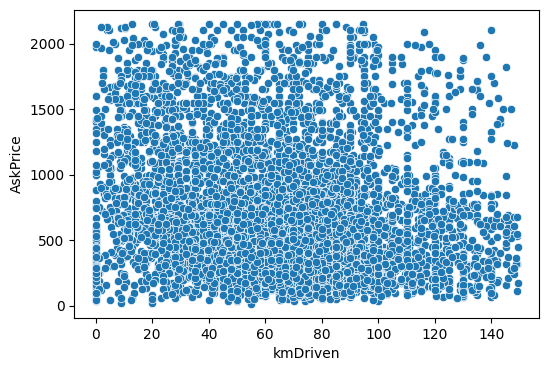

In [ ]:
plt.figure(figsize=(6,4))
sns.scatterplot(df,x=df['kmDriven'],y=df['AskPrice'])

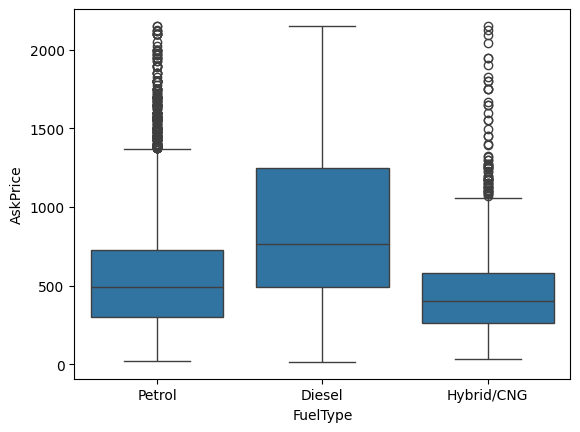

In [ ]:
sns.boxplot(data=df, x="FuelType", y="AskPrice")
plt.show()

In [ ]:
df = df.drop(df[df['Age'] == 25].index)

In [ ]:
df.columns

Index(['Brand', 'model', 'Age', 'kmDriven', 'Transmission', 'Owner',
       'FuelType', 'AskPrice'],
      dtype='object')

In [ ]:
X = df.drop(columns=["AskPrice"])
y = np.log1p(df["AskPrice"])          # skew kam karne ke liye

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cat_cols = ["Brand", "model", "FuelType", "Transmission", "Owner"]   # Model add kiya
num_cols = ["Age", "kmDriven"]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10),
     cat_cols),
    ("num", StandardScaler(), num_cols),
])

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    pipe = Pipeline([
        ("prep", preprocess),      # same preprocessing sab ke liye
        ("model", model),
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    actual_price = np.expm1(y_test)    # log se wapas asli price
    pred_price = np.expm1(pred)

    results.append({
        "model": name,
        "R2 (log)": r2_score(y_test, pred),
        "MAE": mean_absolute_error(actual_price, pred_price),
        "MedAE": median_absolute_error(actual_price, pred_price),
    })

pd.DataFrame(results).sort_values("MAE")

,model,R2 (log),MAE,MedAE
3,RandomForest,0.847706,109.290539,66.500678
1,Ridge,0.863575,110.296482,67.522502
0,LinearRegression,0.863176,110.694915,68.067928
2,Lasso,0.820289,134.040781,85.590481
4,GradientBoosting,0.801337,150.841061,94.521587
